# Task 6 - Supervised and Unsupervised learning techniques

## K Means Clustering -



### EDA Before Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pgs = pd.read_csv('penguins.csv')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
species_colors = {'Adelie': 'tab:blue', 'Chinstrap': 'tab:orange', 'Gentoo': 'tab:green'}

print("Shape:", pgs.shape)
print(pgs.head())
pgs.info()
print(pgs.describe())
print("\nMissing Values:")
print(pgs.isnull().sum())
print("\nDuplicate Rows:", pgs.duplicated().sum())
print("\nSpecies Counts:")
print(pgs['species'].value_counts())

Shape: (344, 9)
   Unnamed: 0 species     island  bill_length_mm  bill_depth_mm  \
0           1  Adelie  Torgersen            39.1           18.7   
1           2  Adelie  Torgersen            39.5           17.4   
2           3  Adelie  Torgersen            40.3           18.0   
3           4  Adelie  Torgersen             NaN            NaN   
4           5  Adelie  Torgersen            36.7           19.3   

   flipper_length_mm  body_mass_g     sex  year  
0              181.0       3750.0    male  2007  
1              186.0       3800.0  female  2007  
2              195.0       3250.0  female  2007  
3                NaN          NaN     NaN  2007  
4              193.0       3450.0  female  2007  
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         344 non-null    int64  
 1   species            344 non-null    str 

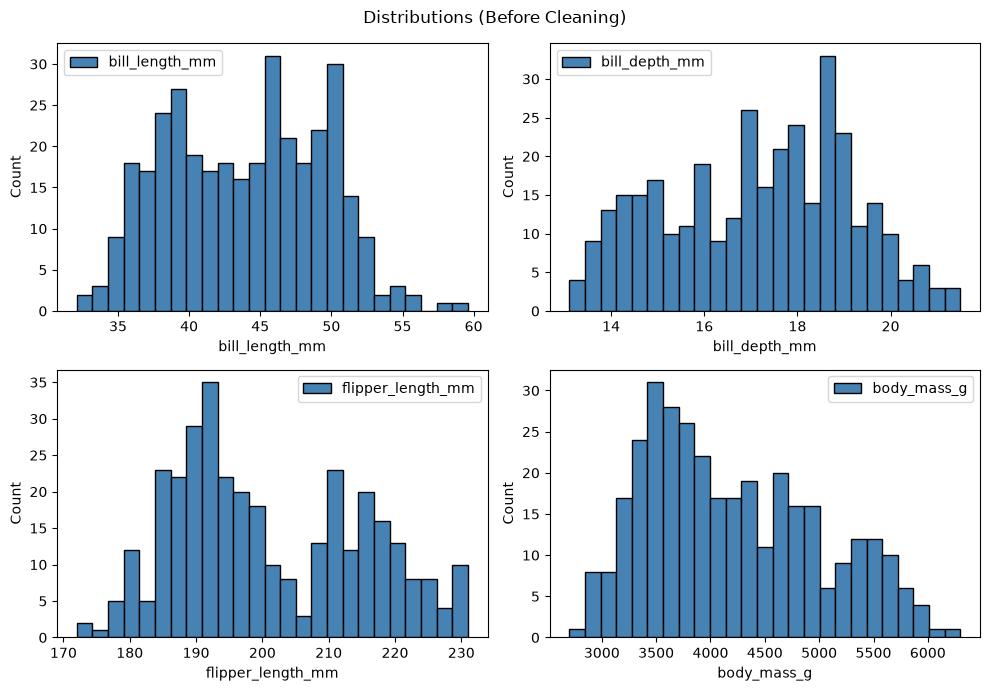

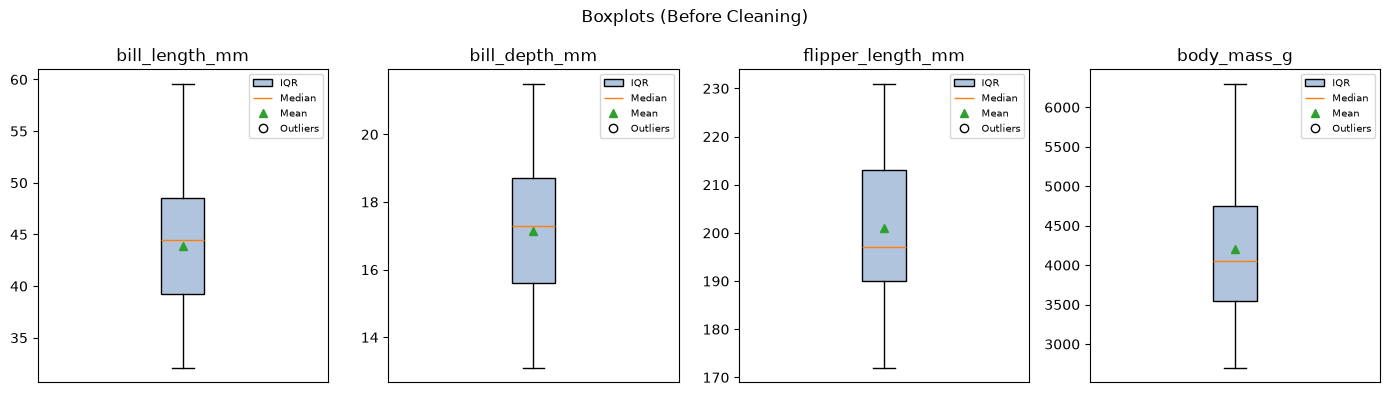

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), num_cols):
    data = pgs[col].dropna()
    ax.hist(data, bins=25, color='steelblue', edgecolor='black', label=col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.legend()
fig.suptitle('Distributions (Before Cleaning)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(pgs[col].dropna(), showmeans=True, patch_artist=True)
    bp['boxes'][0].set_facecolor('lightsteelblue')
    ax.set_xticks([])
    ax.set_title(col)
    ax.legend([bp['boxes'][0], bp['medians'][0], bp['means'][0], bp['fliers'][0]],
              ['IQR', 'Median', 'Mean', 'Outliers'], fontsize=7)
fig.suptitle('Boxplots (Before Cleaning)')
plt.tight_layout()
plt.show()

### Cleaning

In [3]:
pgs = pgs.drop(columns=['Unnamed: 0', 'year'], errors='ignore')
pgs = pgs.dropna(subset=num_cols)
pgs['sex'] = pgs['sex'].fillna('unknown')
pgs = pgs.reset_index(drop=True)
pgs.to_csv('penguins_cleaned.csv', index=False)

print("Shape after cleaning:", pgs.shape)
print("Missing values left:", pgs.isnull().sum().sum())

Shape after cleaning: (342, 7)
Missing values left: 0


### EDA After Cleaning

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      342.000000     342.000000         342.000000   342.000000
mean        43.921930      17.151170         200.915205  4201.754386
std          5.459584       1.974793          14.061714   801.954536
min         32.100000      13.100000         172.000000  2700.000000
25%         39.225000      15.600000         190.000000  3550.000000
50%         44.450000      17.300000         197.000000  4050.000000
75%         48.500000      18.700000         213.000000  4750.000000
max         59.600000      21.500000         231.000000  6300.000000

Species Counts:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

Correlation:
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm               1.00          -0.24               0.66   
bill_depth_mm               -0.24           1.00              -0.58   
flipper_length_mm            0.66          -0.58  

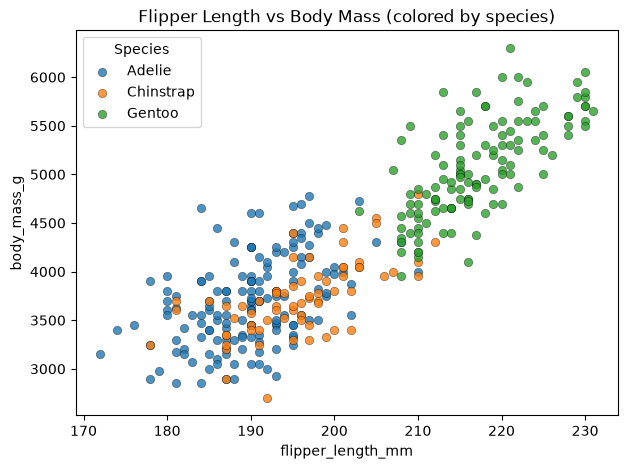

In [4]:
print(pgs[num_cols].describe())
print("\nSpecies Counts:")
print(pgs['species'].value_counts())
print("\nCorrelation:")
print(pgs[num_cols].corr().round(2))

fig, ax = plt.subplots(figsize=(7, 5))
for sp, color in species_colors.items():
    sub = pgs[pgs['species'] == sp]
    ax.scatter(sub['flipper_length_mm'], sub['body_mass_g'], c=color, label=sp, alpha=0.8, edgecolor='black', linewidth=0.3)
ax.set_xlabel('flipper_length_mm')
ax.set_ylabel('body_mass_g')
ax.set_title('Flipper Length vs Body Mass (colored by species)')
ax.legend(title='Species')
plt.show()

## K Means Clustering

k = 2 | Inertia: 565.71 | Silhouette: 0.532
k = 3 | Inertia: 379.39 | Silhouette: 0.447
k = 4 | Inertia: 300.52 | Silhouette: 0.4
k = 5 | Inertia: 232.6 | Silhouette: 0.378
k = 6 | Inertia: 204.39 | Silhouette: 0.368
k = 7 | Inertia: 187.16 | Silhouette: 0.334
k = 8 | Inertia: 170.98 | Silhouette: 0.296


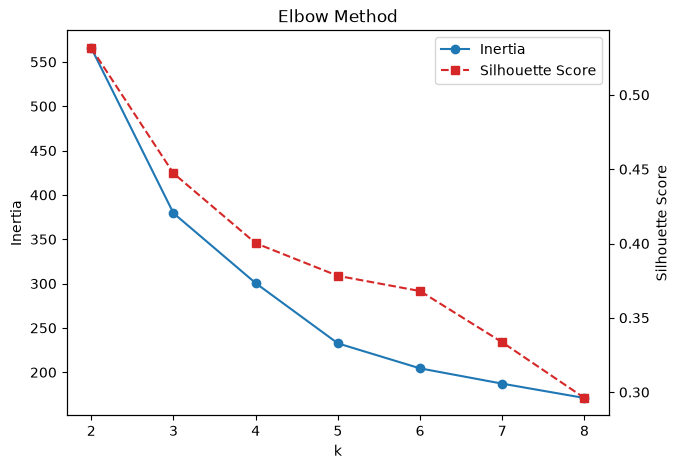

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(pgs[num_cols])

ks = list(range(2, 9))
inertia = []
silhouettes = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=1).fit(X)
    sil = silhouette_score(X, model.labels_)
    inertia.append(model.inertia_)
    silhouettes.append(sil)
    print("k =", k, "| Inertia:", round(model.inertia_, 2), "| Silhouette:", round(sil, 3))

fig, ax1 = plt.subplots(figsize=(7, 5))
line1 = ax1.plot(ks, inertia, marker='o', color='tab:blue', label='Inertia')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia')
ax2 = ax1.twinx()
line2 = ax2.plot(ks, silhouettes, marker='s', linestyle='--', color='tab:red', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score')
lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc='upper right')
plt.title('Elbow Method')
plt.show()

Inertia: 379.39
Silhouette Score: 0.447

Cluster vs Species:
species  Adelie  Chinstrap  Gentoo
cluster                           
0           127          5       0
1             0          0     123
2            24         63       0

Cluster Purity: 0.915


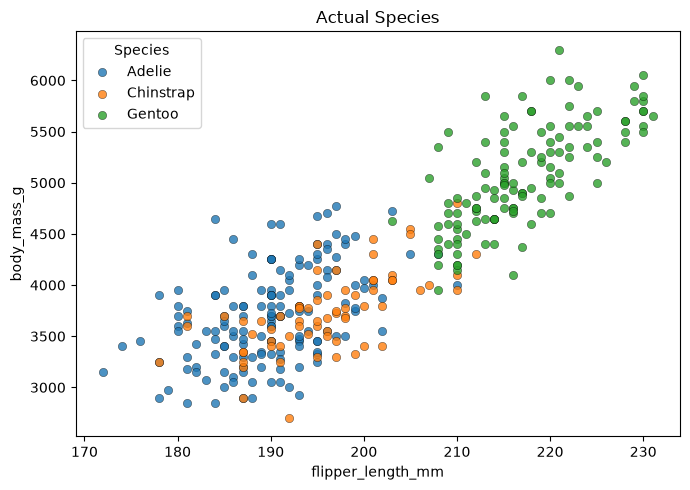

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=1).fit(X)
pgs['cluster'] = km.labels_

print("Inertia:", round(km.inertia_, 2))
print("Silhouette Score:", round(silhouette_score(X, km.labels_), 3))

table = pd.crosstab(pgs['cluster'], pgs['species'])
print("\nCluster vs Species:")
print(table)
print("\nCluster Purity:", round(table.max(axis=1).sum() / len(pgs), 3))

fig, ax = plt.subplots(figsize=(7, 5))

for sp, color in species_colors.items():
    sub = pgs[pgs['species'] == sp]
    ax.scatter(sub['flipper_length_mm'], sub['body_mass_g'], c=color, label=sp, alpha=0.8, edgecolor='black', linewidth=0.3)

ax.set_title('Actual Species')
ax.set_xlabel('flipper_length_mm')
ax.set_ylabel('body_mass_g')
ax.legend(title='Species')

plt.tight_layout()
plt.show()

## Decision trees-

### EDA Before Cleaning

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, recall_score, matthews_corrcoef, roc_auc_score, confusion_matrix, classification_report

drug = pd.read_csv('drug200.csv')
num_cols = ['Age', 'Na_to_K']
cat_cols = ['Sex', 'BP', 'Cholesterol']
drug_colors = {'drugA': 'tab:blue', 'drugB': 'tab:orange', 'drugC': 'tab:green', 'drugX': 'tab:red', 'drugY': 'tab:purple'}

print("Shape:", drug.shape)
print(drug.head())
drug.info()
print(drug.describe())
print("\nMissing Values:")
print(drug.isnull().sum())
print("\nDuplicate Rows:", drug.duplicated().sum())
print("\nDrug Counts:")
print(drug['Drug'].value_counts())
for col in cat_cols:
    print("\n" + col + " Counts:")
    print(drug[col].value_counts())

Shape: (200, 6)
   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB
              Age     Na_to_K
count  200.000000  200.000000
mean    44.315000   16.084485
std     16.544315    7.223956
min     15.000000    6.269000
25%     31.000000   10.445500
50%     45.000000   13.936500
75%  

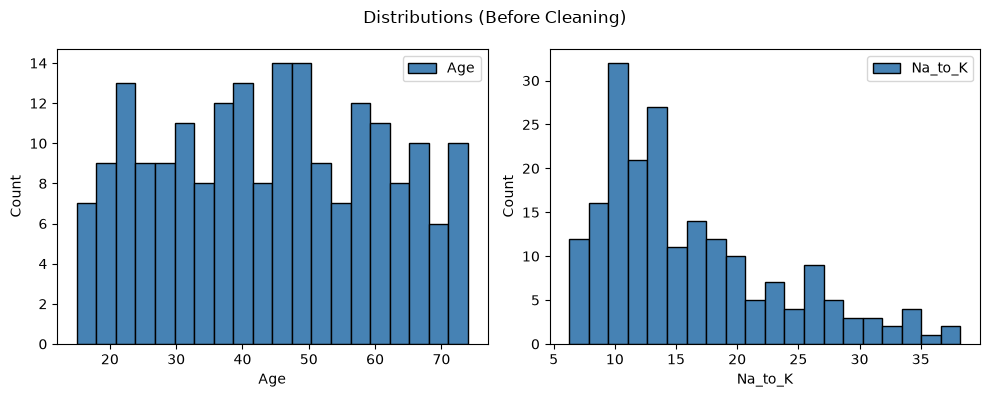

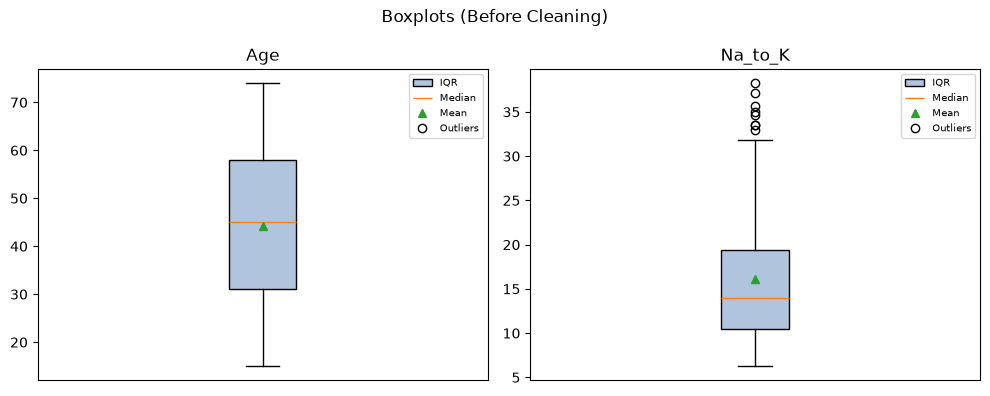

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    ax.hist(drug[col], bins=20, color='steelblue', edgecolor='black', label=col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.legend()
fig.suptitle('Distributions (Before Cleaning)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(drug[col], showmeans=True, patch_artist=True)
    bp['boxes'][0].set_facecolor('lightsteelblue')
    ax.set_xticks([])
    ax.set_title(col)
    ax.legend([bp['boxes'][0], bp['medians'][0], bp['means'][0], bp['fliers'][0]],
              ['IQR', 'Median', 'Mean', 'Outliers'], fontsize=7)
fig.suptitle('Boxplots (Before Cleaning)')
plt.tight_layout()
plt.show()

### Cleaning

In [9]:
for col in cat_cols + ['Drug']:
    drug[col] = drug[col].str.strip().str.upper() if col != 'Drug' else drug[col].str.strip()

drug = drug.drop_duplicates()
drug = drug.dropna()

drug['Sex'] = drug['Sex'].map({'F': 0, 'M': 1})
drug['BP'] = drug['BP'].map({'LOW': 0, 'NORMAL': 1, 'HIGH': 2})
drug['Cholesterol'] = drug['Cholesterol'].map({'NORMAL': 0, 'HIGH': 1})
drug = drug.reset_index(drop=True)
drug.to_csv('drug200_cleaned.csv', index=False)

print("Shape after cleaning:", drug.shape)
print("Missing values left:", drug.isnull().sum().sum())
print(drug.head())

Shape after cleaning: (200, 6)
Missing values left: 0
   Age  Sex  BP  Cholesterol  Na_to_K   Drug
0   23    0   2            1   25.355  drugY
1   47    1   0            1   13.093  drugC
2   47    1   0            1   10.114  drugC
3   28    0   1            1    7.798  drugX
4   61    0   0            1   18.043  drugY


### EDA After Cleaning

              Age         Sex          BP  Cholesterol     Na_to_K
count  200.000000  200.000000  200.000000   200.000000  200.000000
mean    44.315000    0.520000    1.065000     0.515000   16.084485
std     16.544315    0.500854    0.839224     0.501029    7.223956
min     15.000000    0.000000    0.000000     0.000000    6.269000
25%     31.000000    0.000000    0.000000     0.000000   10.445500
50%     45.000000    1.000000    1.000000     1.000000   13.936500
75%     58.000000    1.000000    2.000000     1.000000   19.380000
max     74.000000    1.000000    2.000000     1.000000   38.247000

Drug Counts:
Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

Correlation:
              Age   Sex    BP  Cholesterol  Na_to_K
Age          1.00  0.10 -0.12         0.07    -0.06
Sex          0.10  1.00 -0.04         0.01    -0.13
BP          -0.12 -0.04  1.00        -0.03     0.04
Cholesterol  0.07  0.01 -0.03         1.00    -0.01
Na_to_K     -0.06 

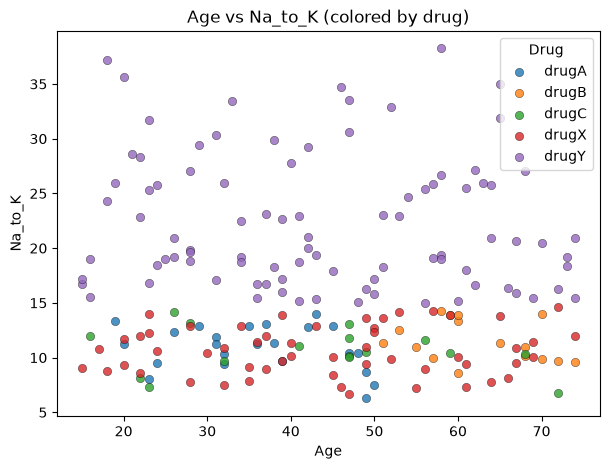

In [10]:
print(drug.describe())
print("\nDrug Counts:")
print(drug['Drug'].value_counts())
print("\nCorrelation:")
print(drug[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']].corr().round(2))
print("\nMean Na_to_K per Drug:")
print(drug.groupby('Drug')['Na_to_K'].mean().round(2))

fig, ax = plt.subplots(figsize=(7, 5))
for d, color in drug_colors.items():
    sub = drug[drug['Drug'] == d]
    ax.scatter(sub['Age'], sub['Na_to_K'], c=color, label=d, alpha=0.8, edgecolor='black', linewidth=0.3)
ax.set_xlabel('Age')
ax.set_ylabel('Na_to_K')
ax.set_title('Age vs Na_to_K (colored by drug)')
ax.legend(title='Drug')
plt.show()

## Decision Trees

In [11]:
X = drug[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']]
y = drug['Drug']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

Train Shape: (160, 5)
Test Shape: (40, 5)


max_depth = 1 | Train Accuracy: 0.725 | Test Accuracy: 0.725
max_depth = 2 | Train Accuracy: 0.838 | Test Accuracy: 0.85
max_depth = 3 | Train Accuracy: 0.919 | Test Accuracy: 0.925
max_depth = 4 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 5 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 6 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 7 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 8 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 9 | Train Accuracy: 1.0 | Test Accuracy: 1.0
max_depth = 10 | Train Accuracy: 1.0 | Test Accuracy: 1.0


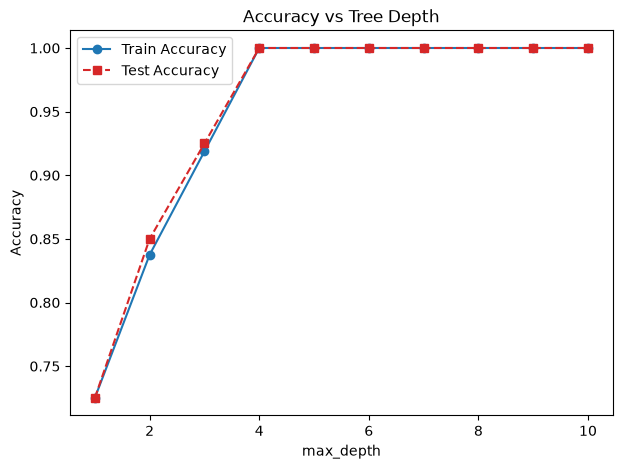

In [12]:
depths = list(range(1, 11))
train_acc = []
test_acc = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=1).fit(X_train, y_train)
    train_acc.append(tree.score(X_train, y_train))
    test_acc.append(tree.score(X_test, y_test))
    print("max_depth =", d, "| Train Accuracy:", round(train_acc[-1], 3), "| Test Accuracy:", round(test_acc[-1], 3))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(depths, train_acc, marker='o', color='tab:blue', label='Train Accuracy')
ax.plot(depths, test_acc, marker='s', linestyle='--', color='tab:red', label='Test Accuracy')
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy vs Tree Depth')
ax.legend()
plt.show()

In [13]:
params = {'max_depth': [2, 3, 4, 5, 6], 'criterion': ['gini', 'entropy'], 'min_samples_leaf': [1, 2, 3]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=1), params, cv=5, scoring='f1_macro')  
#JSB: Macro means calculate the score separately for each class, then take the plain average of those scores, so every class counts equally
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1 (macro):", round(grid.best_score_, 3))

Best Parameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1}
Best CV F1 (macro): 0.984


Accuracy: 1.0
F1 Score (macro): 1.0
Recall (macro): 1.0
MCC: 1.0
AUC : 1.0

Classification Report:
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



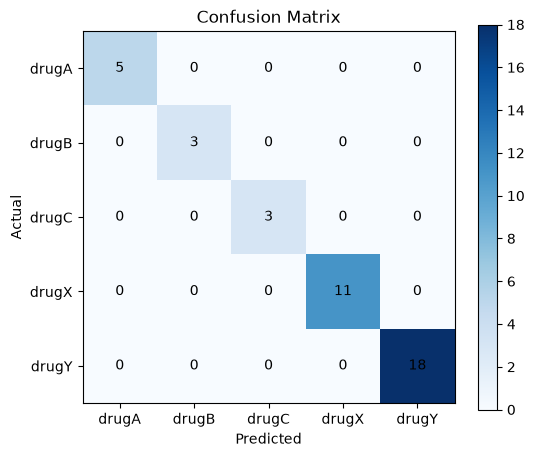

In [14]:
model = grid.best_estimator_
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("F1 Score (macro):", round(f1_score(y_test, y_pred, average='macro'), 3))
print("Recall (macro):", round(recall_score(y_test, y_pred, average='macro'), 3))
print("MCC:", round(matthews_corrcoef(y_test, y_pred), 3))
print("AUC :", round(roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro'), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im)
ax.set_xticks(range(len(model.classes_)))
ax.set_xticklabels(model.classes_)
ax.set_yticks(range(len(model.classes_)))
ax.set_yticklabels(model.classes_)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, cm[i, j], ha='center', va='center')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix')
plt.show()

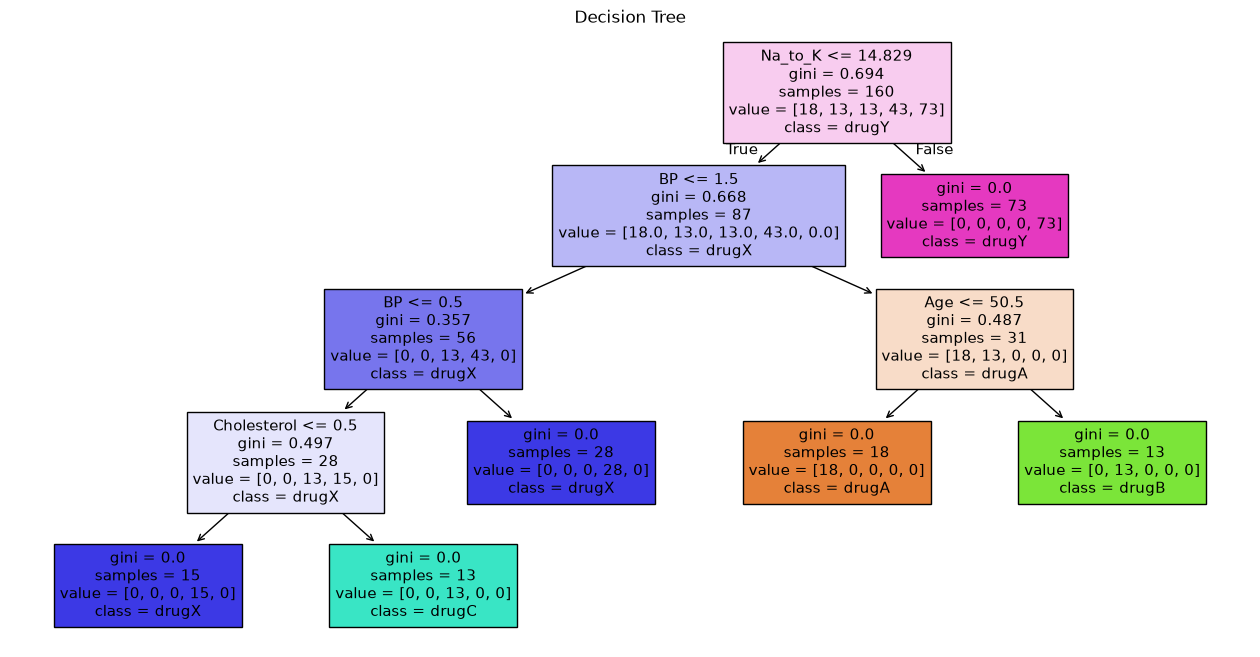

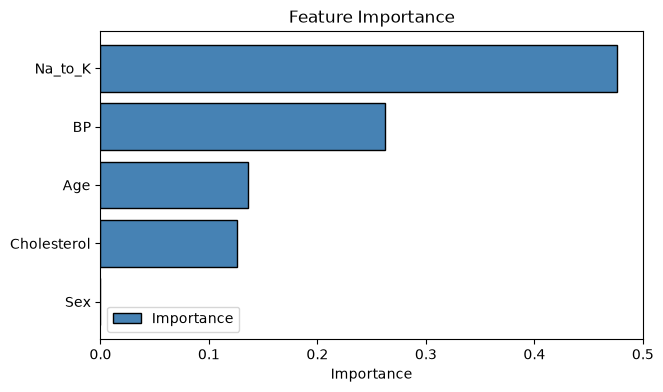

In [15]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, ax=ax)
ax.set_title('Decision Tree')
plt.show()

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color='steelblue', edgecolor='black', label='Importance')
ax.set_xlabel('Importance')
ax.set_title('Feature Importance')
ax.legend()
plt.show()